# 08 · Dinámica espacio-temporal y aprendizaje automático espacial

| | |
|---|---|
| **Pregunta** | ¿Cómo se expandió la red de canales entre 2017 y 2025, se difunde por contigüidad, es predecible su cambio anual, y qué distritos tienen menos acceso del que corresponde a su estructura? |
| **Datos** | Panel SBS de cajeros automáticos, establecimientos con cajeros corresponsales y EOB por distrito (todas las entidades), cierres de diciembre 2017 a 2025: 327 distritos × 9 años. |
| **Métodos** | I de Moran por año; cadenas de Markov clásicas y espaciales (Rey, 2001) con prueba de homogeneidad; predicción del cambio anual con validación de origen móvil frente a persistencia; modelo de acceso potencial (Ridge, Random Forest, XGBoost) con rezagos espaciales de covariables y validación cruzada espacial por bloques provinciales; interpretación con valores SHAP. |
| **Salidas** | `outputs/figuras/08_*.png` · `outputs/tablas/08_*.csv` · `data/processed/brecha_acceso_2025.csv`. |

**Supuesto:** la población adulta de 2025 se usa como denominador en todos los años (no hay serie distrital
anual oficial). Las tasas reflejan sobre todo el cambio en la oferta, no en la población.

In [1]:
from pathlib import Path
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import xgboost as xgb
from esda import Moran
from giddy.markov import Markov, Spatial_Markov
from libpysal import weights
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 2026
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
FIG = ROOT / "outputs" / "figuras"
TAB = ROOT / "outputs" / "tablas"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORES_DEP = {"TUMBES": "#1b9e77", "PIURA": "#d95f02", "LAMBAYEQUE": "#7570b3",
               "LA LIBERTAD": "#e7298a", "CAJAMARCA": "#66a61e"}

/sessions/rcw-01lunysqylmxk5xagddf3uwd/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Construcción del panel

In [2]:
g = gpd.read_file(DATA / "geobanca_norte.gpkg", layer="distritos").to_crs("EPSG:32717").reset_index(drop=True)
lisa = pd.read_csv(DATA / "lisa_acceso.csv", dtype={"ubigeo": str})[["ubigeo", "pobreza_imp"]]
g = g.merge(lisa, on="ubigeo", how="left")
g["altitud_km"] = g["altitud_capital_m"].fillna(g["altitud_capital_m"].mean()) / 1000
g["log_densidad"] = np.log(g["densidad_hab_km2"])

w = weights.Queen.from_dataframe(g, use_index=False)
w.transform = "r"

raw = pd.read_csv(DATA / "sbs_puntos_atencion_panel_distrito.csv", dtype={"ubigeo": str})
raw = raw[raw["corte"].str.startswith("di")].copy()
raw["anio"] = raw["corte"].str[2:].astype(int)
raw["canales"] = raw["atm"] + raw["corresponsal_establecimientos"] + raw["eob"]

ANIOS = sorted(raw["anio"].unique())
idx = pd.MultiIndex.from_product([g["ubigeo"], ANIOS], names=["ubigeo", "anio"])
panel = (raw.set_index(["ubigeo", "anio"])[["canales", "atm", "corresponsal_establecimientos"]]
            .reindex(idx, fill_value=0).reset_index())
panel = panel.merge(g[["ubigeo", "departamento", "provincia", "pob_18mas"]], on="ubigeo")
panel["tasa"] = 1e4 * panel["canales"] / panel["pob_18mas"]
panel["y"] = np.log1p(panel["tasa"])                  # escala de modelado
print(f"Panel: {panel['ubigeo'].nunique()} distritos × {len(ANIOS)} años = {len(panel)} filas")

# Matriz distrito × año en el orden de g (necesaria para Moran y Markov)
Y = panel.pivot(index="ubigeo", columns="anio", values="y").loc[g["ubigeo"]]
TASA = panel.pivot(index="ubigeo", columns="anio", values="tasa").loc[g["ubigeo"]]

Panel: 327 distritos × 9 años = 2943 filas


## 2. Evolución de la red y de su dependencia espacial

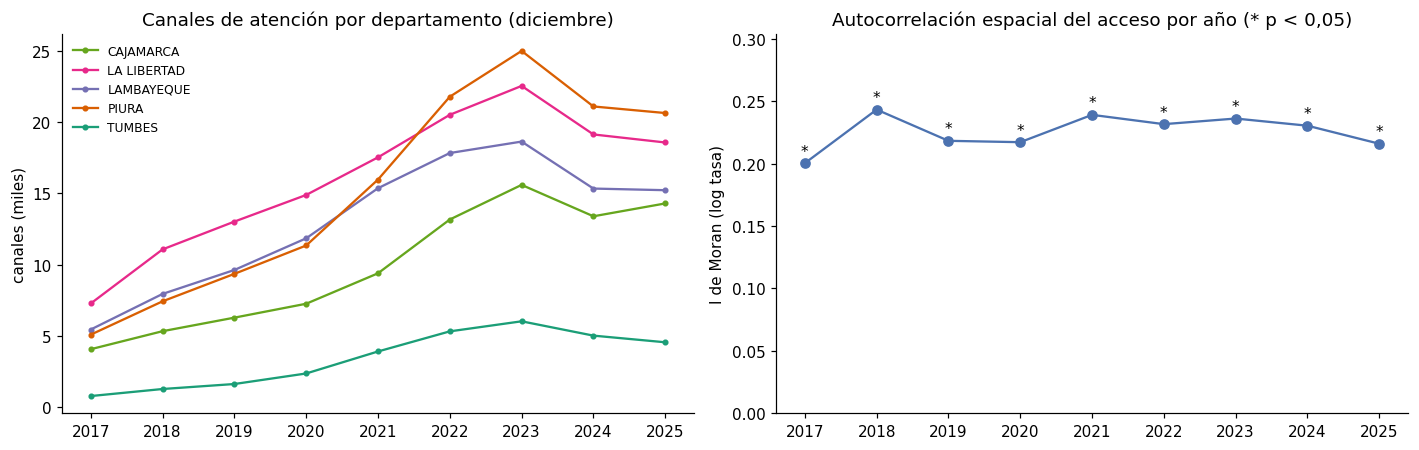

anio,2017,2018,2019,2020,2021,2022,2023,2024,2025
I,0.200,0.243,0.218,0.217,0.239,0.232,0.236,0.230,0.216
p,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001


In [3]:
tot = panel.groupby(["anio", "departamento"])["canales"].sum().unstack()
moran_t = pd.DataFrame([{"anio": a, "I": (m := Moran(Y[a], w, permutations=999)).I, "p": m.p_sim} for a in ANIOS]).set_index("anio")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for dep in tot.columns:
    axes[0].plot(tot.index, tot[dep] / 1000, marker="o", markersize=3, color=COLORES_DEP[dep], label=dep)
axes[0].set_ylabel("canales (miles)"); axes[0].set_title("Canales de atención por departamento (diciembre)")
axes[0].legend(frameon=False, fontsize=8)
axes[1].plot(moran_t.index, moran_t["I"], marker="o", color="#4c72b0")
for a, r in moran_t.iterrows():
    axes[1].annotate("*" if r.p < 0.05 else "", (a, r.I), textcoords="offset points", xytext=(0, 5), ha="center")
axes[1].set_ylim(0, moran_t["I"].max() * 1.25); axes[1].set_ylabel("I de Moran (log tasa)")
axes[1].set_title("Autocorrelación espacial del acceso por año (* p < 0,05)")
fig.tight_layout()
fig.savefig(FIG / "08_evolucion_moran.png", bbox_inches="tight")
plt.show()
moran_t.round(3).T

## 3. Cadenas de Markov espaciales

Cada distrito se clasifica cada año en quintiles de acceso. La **cadena de Markov clásica** estima la probabilidad
de pasar de un quintil a otro entre años consecutivos. La **cadena de Markov espacial** (Rey, 2001) estima esas
transiciones condicionadas al quintil del rezago espacial (el promedio de los vecinos). Si las matrices
condicionales difieren, el entorno influye en la trayectoria: hay **difusión espacial**.

In [4]:
import mapclassify as mc
q = np.column_stack([mc.Quantiles(Y[a], k=5).yb for a in ANIOS])   # quintiles de cada año
mk = Markov(q)
etq = ["Q1 (bajo)", "Q2", "Q3", "Q4", "Q5 (alto)"]
print("Markov clásica: probabilidades de transición anual")
print(pd.DataFrame(mk.p, index=etq, columns=etq).round(3).to_string())

sm_ = Spatial_Markov(np.asarray(Y), w, fixed=False, k=5, m=5)
print(f"\nPrueba de homogeneidad espacial (Bickenbach y Bode): Q = {sm_.Q:.1f}, gl = {sm_.dof_hom}, p = {sm_.Q_p_value:.4f}")
print(f"Razón de verosimilitudes: LR = {sm_.LR:.1f}, p = {sm_.LR_p_value:.4f}")

The Markov Chain is irreducible and is composed by:
1 Recurrent class (indices):
[0 1 2 3 4]
0 Transient classes.
The Markov Chain has 0 absorbing states.
Markov clásica: probabilidades de transición anual
           Q1 (bajo)     Q2     Q3     Q4  Q5 (alto)
Q1 (bajo)      0.788  0.152  0.045  0.011      0.004
Q2             0.200  0.629  0.125  0.035      0.012
Q3             0.010  0.192  0.600  0.175      0.023
Q4             0.002  0.021  0.217  0.613      0.146
Q5 (alto)      0.004  0.004  0.011  0.163      0.818

Prueba de homogeneidad espacial (Bickenbach y Bode): Q = 146.3, gl = 80, p = 0.0000
Razón de verosimilitudes: LR = 124.3, p = 0.0011


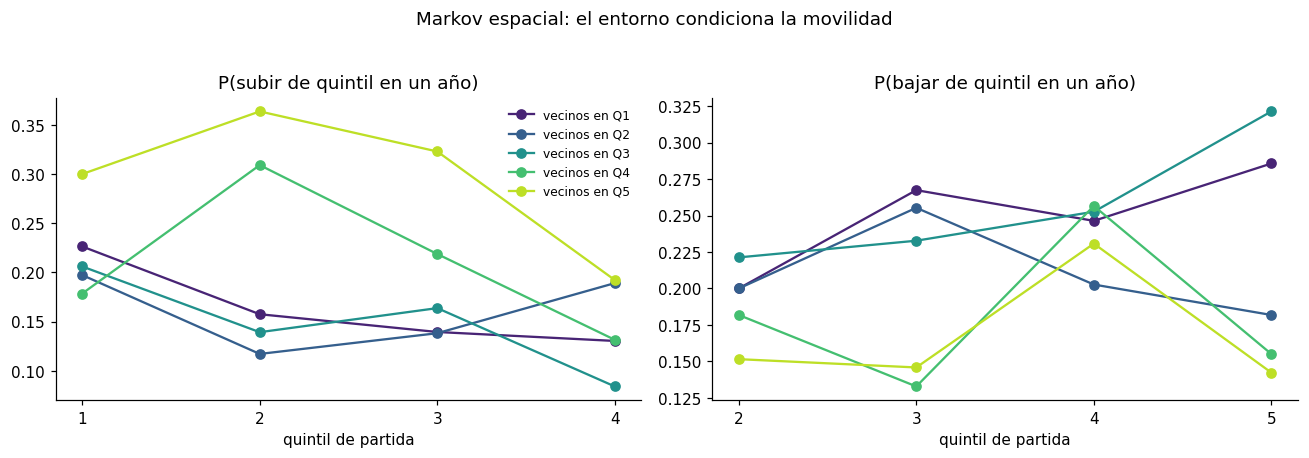

In [5]:
# Probabilidad de subir de quintil según el entorno
def prob_subir(P):
    return np.array([P[i, i + 1:].sum() for i in range(4)])
def prob_bajar(P):
    return np.array([P[i, :i].sum() for i in range(1, 5)])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cols = plt.cm.viridis(np.linspace(0.1, 0.9, 5))
for k in range(5):
    axes[0].plot(range(1, 5), prob_subir(sm_.P[k]), marker="o", color=cols[k], label=f"vecinos en Q{k+1}")
    axes[1].plot(range(2, 6), prob_bajar(sm_.P[k]), marker="o", color=cols[k], label=f"vecinos en Q{k+1}")
axes[0].set_xticks(range(1, 5)); axes[0].set_xlabel("quintil de partida"); axes[0].set_title("P(subir de quintil en un año)")
axes[1].set_xticks(range(2, 6)); axes[1].set_xlabel("quintil de partida"); axes[1].set_title("P(bajar de quintil en un año)")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Markov espacial: el entorno condiciona la movilidad", y=1.03)
fig.tight_layout()
fig.savefig(FIG / "08_markov_espacial.png", bbox_inches="tight")
plt.show()

## 4. ¿Se puede anticipar el cambio anual de cada distrito?

**Diseño de origen móvil.** Para cada año de prueba t ∈ {2021, …, 2024} se entrena con todas las transiciones
anteriores y se predice el cambio de la log tasa entre t y t+1. Las variables son la log tasa en t, el cambio
t−1 → t, la participación de ATM, los rezagos espaciales (nivel y cambio de los vecinos) y las covariables
estructurales. El punto de comparación es la **persistencia** (cambio = 0), un estándar exigente en paneles cortos.

Además del RMSE se reporta la correlación de rangos de Spearman entre el cambio predicho y el observado: mide si
el modelo **ordena** bien qué distritos crecerán más, que es lo que importaría para priorizar.

In [6]:
WY = pd.DataFrame(weights.lag_spatial(w, Y.to_numpy()), index=Y.index, columns=Y.columns)
filas = []
for i, a in enumerate(ANIOS[1:-1], start=1):
    a_prev, a_next = ANIOS[i - 1], ANIOS[i + 1]
    filas.append(pd.DataFrame({
        "ubigeo": Y.index, "anio": a,
        "y_t": Y[a].to_numpy(), "dy_t": (Y[a] - Y[a_prev]).to_numpy(),
        "wy_t": WY[a].to_numpy(), "wdy_t": (WY[a] - WY[a_prev]).to_numpy(),
        "y_next": Y[a_next].to_numpy()}))
ds = pd.concat(filas, ignore_index=True)
ds = ds.merge(panel[["ubigeo", "anio", "atm", "canales"]], on=["ubigeo", "anio"], how="left")
ds["share_atm"] = np.where(ds["canales"] > 0, ds["atm"] / ds["canales"], 0)
ds = ds.merge(g[["ubigeo", "provincia", "pobreza_imp", "pct_urbana", "altitud_km", "log_densidad"]], on="ubigeo")
ds["delta"] = ds["y_next"] - ds["y_t"]

print("Cambio medio de la log tasa por año (choque común a todos los distritos):")
print(ds.groupby("anio")["delta"].mean().rename(lambda a: f"{a}→{a+1}").round(3).to_string())

Cambio medio de la log tasa por año (choque común a todos los distritos):
anio
2018→2019    0.231
2019→2020    0.002
2020→2021    0.539
2021→2022    0.323
2022→2023    0.191
2023→2024   -0.070
2024→2025    0.053


In [7]:
from scipy.stats import spearmanr
F_DIN = ["y_t", "dy_t", "share_atm", "wy_t", "wdy_t", "pobreza_imp", "pct_urbana", "altitud_km", "log_densidad"]

def modelos(semilla=SEED):
    return {
        "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 25))),
        "Random Forest": RandomForestRegressor(n_estimators=400, min_samples_leaf=10, n_jobs=-1, random_state=semilla),
        "XGBoost": xgb.XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8,
                                    min_child_weight=10, random_state=semilla),
    }

res = []
for ta in ANIOS[4:-1]:
    tr, te = ds[ds["anio"] < ta], ds[ds["anio"] == ta]
    fila = {"prueba": f"{ta}→{ta + 1}", "Persistencia RMSE": mean_squared_error(te["y_next"], te["y_t"]) ** 0.5}
    for nombre, m in modelos().items():
        m.fit(tr[F_DIN], tr["delta"])
        d_hat = m.predict(te[F_DIN])
        fila[f"{nombre} RMSE"] = mean_squared_error(te["y_next"], te["y_t"] + d_hat) ** 0.5
        fila[f"{nombre} ρ Spearman"] = spearmanr(d_hat, te["delta"])[0]
    res.append(fila)
origen_movil = pd.DataFrame(res).set_index("prueba")
origen_movil.loc["Promedio"] = origen_movil.mean()
origen_movil.round(3).to_csv(TAB / "08_prediccion_cambio_anual.csv")
origen_movil.round(3)

,Persistencia RMSE,Ridge RMSE,Ridge ρ Spearman,Random Forest RMSE,Random Forest ρ Spearman,XGBoost RMSE,XGBoost ρ Spearman
prueba,,,,,,,
2021→2022,0.586,0.670,-0.071,0.651,-0.003,0.683,-0.042
2022→2023,0.647,0.601,-0.134,0.579,0.123,0.590,0.019
2023→2024,0.521,0.554,0.117,0.529,0.129,0.535,-0.005
2024→2025,0.482,0.463,-0.013,0.480,0.084,0.468,0.098
Promedio,0.559,0.572,-0.025,0.560,0.083,0.569,0.017


**Lectura.** El error de todos los modelos es del mismo orden que el de la persistencia y la correlación de rangos
del cambio es cercana a cero: la variación anual de cada distrito está dominada por choques comunes (expansión de
2020-2021, retroceso de 2023) y por ruido idiosincrático, no por su estructura ni por su entorno. La conclusión
operativa es que **no conviene priorizar distritos según su crecimiento esperado**, sino según la brecha entre su
nivel de acceso y el que corresponde a su estructura, que es lo que modela la sección siguiente.

## 5. Acceso potencial y brecha: modelo transversal con validación cruzada espacial

Se estima el acceso **esperado** de cada distrito en 2025 a partir de su estructura (pobreza, urbanización,
altitud, densidad), del promedio de esas variables en sus vecinos (WX) y de su posición (coordenadas UTM).
Las predicciones son **fuera de pliegue** con 5 pliegues agrupados por provincia: el acceso esperado de un
distrito se calcula con un modelo que nunca vio su provincia, lo que evita que la autocorrelación espacial
infle el ajuste (Roberts et al., 2017).

**Brecha = log tasa observada − log tasa esperada.** Una brecha negativa identifica distritos **desatendidos
respecto de distritos comparables**: oportunidad comercial que no depende de la pobreza en sí.

In [8]:
corte = g[["ubigeo", "distrito", "provincia", "departamento", "pobreza_imp", "pct_urbana", "altitud_km", "log_densidad"]].copy()
corte["y"] = Y[ANIOS[-1]].to_numpy()
cent = g.geometry.centroid
corte["x_km"], corte["y_km"] = cent.x.to_numpy() / 1000, cent.y.to_numpy() / 1000
F_EST = ["pobreza_imp", "pct_urbana", "altitud_km", "log_densidad"]
for c in F_EST:
    corte[f"W_{c}"] = weights.lag_spatial(w, corte[c].to_numpy())
conj = {"estructurales (X)": F_EST,
        "X + rezagos espaciales (WX)": F_EST + [f"W_{c}" for c in F_EST],
        "X + WX + coordenadas": F_EST + [f"W_{c}" for c in F_EST] + ["x_km", "y_km"]}

gkf = GroupKFold(n_splits=5)
oof, filas = {}, []
for nc, cols in conj.items():
    for nm, _ in modelos().items():
        p = np.zeros(len(corte))
        for tr, va in gkf.split(corte, groups=corte["provincia"]):
            m = modelos()[nm].fit(corte.iloc[tr][cols], corte.iloc[tr]["y"])
            p[va] = m.predict(corte.iloc[va][cols])
        oof[(nm, nc)] = p
        resid = corte["y"].to_numpy() - p
        filas.append({"modelo": nm, "variables": nc,
                      **{"RMSE": mean_squared_error(corte["y"], p) ** 0.5, "MAE": mean_absolute_error(corte["y"], p),
                       "R² (CV espacial)": r2_score(corte["y"], p)},
                      "I de Moran residuos": Moran(resid, w, permutations=999).I})
cv_tab = pd.DataFrame(filas).set_index(["modelo", "variables"])
cv_tab.round(3).to_csv(TAB / "08_acceso_potencial_cv_espacial.csv")
cv_tab.round(3)

,,RMSE,MAE,R² (CV espacial),I de Moran residuos
modelo,variables,,,,
Ridge,estructurales (X),0.964,0.726,0.239,0.124
Random Forest,estructurales (X),0.944,0.704,0.271,0.099
XGBoost,estructurales (X),0.989,0.736,0.200,0.092
Ridge,X + rezagos espaciales (WX),0.932,0.694,0.290,0.131
Random Forest,X + rezagos espaciales (WX),0.926,0.681,0.298,0.092
XGBoost,X + rezagos espaciales (WX),0.989,0.739,0.199,0.107
Ridge,X + WX + coordenadas,0.920,0.690,0.307,0.094
Random Forest,X + WX + coordenadas,0.903,0.659,0.332,0.052
XGBoost,X + WX + coordenadas,0.976,0.725,0.220,0.071


Mejor especificación (CV espacial): ('Random Forest', 'X + WX + coordenadas')


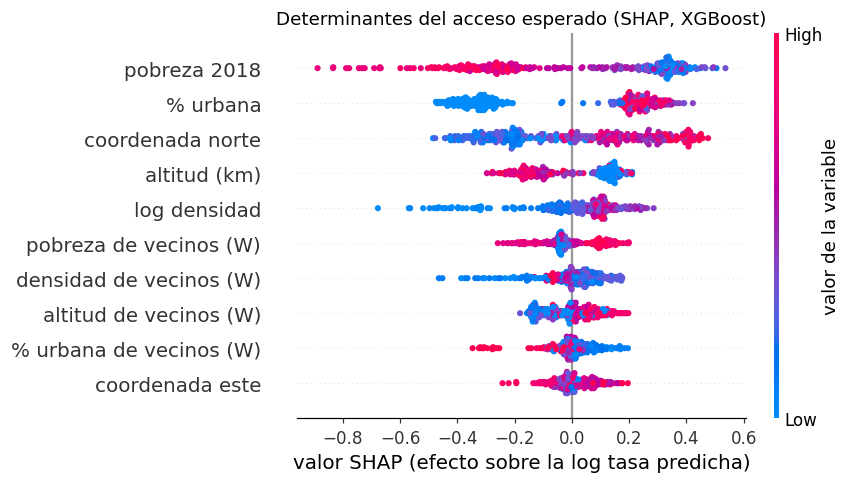

pobreza 2018               0.221
% urbana                   0.204
coordenada norte           0.161
altitud (km)               0.098
log densidad               0.085
pobreza de vecinos (W)     0.054
densidad de vecinos (W)    0.054
altitud de vecinos (W)     0.050
% urbana de vecinos (W)    0.038
coordenada este            0.035
Name: peso relativo |SHAP|, dtype: float32

In [9]:
mejor = cv_tab["RMSE"].idxmin()
print("Mejor especificación (CV espacial):", mejor)
cols = conj[mejor[1]]
corte["y_esperado"] = oof[mejor]
corte["brecha"] = corte["y"] - corte["y_esperado"]
corte["tasa_obs"] = np.expm1(corte["y"])
corte["tasa_esperada"] = np.expm1(corte["y_esperado"])

# Interpretación: modelo ajustado con todos los datos (XGBoost) y SHAP exacto de árboles
xgb_full = modelos()["XGBoost"].fit(corte[cols], corte["y"])
contrib = xgb_full.get_booster().predict(xgb.DMatrix(corte[cols]), pred_contribs=True)
sv = contrib[:, :-1]
nombres = {"pobreza_imp": "pobreza 2018", "pct_urbana": "% urbana", "altitud_km": "altitud (km)",
           "log_densidad": "log densidad", "W_pobreza_imp": "pobreza de vecinos (W)", "W_pct_urbana": "% urbana de vecinos (W)",
           "W_altitud_km": "altitud de vecinos (W)", "W_log_densidad": "densidad de vecinos (W)",
           "x_km": "coordenada este", "y_km": "coordenada norte"}
X_show = corte[cols].rename(columns=nombres)
plt.figure()
shap.summary_plot(sv, X_show, show=False, plot_size=(8, 4.5), color_bar_label="valor de la variable")
plt.title("Determinantes del acceso esperado (SHAP, XGBoost)")
plt.xlabel("valor SHAP (efecto sobre la log tasa predicha)")
plt.tight_layout()
plt.savefig(FIG / "08_shap_acceso_potencial.png", bbox_inches="tight", dpi=300)
plt.show()
imp = pd.Series(np.abs(sv).mean(0), index=X_show.columns).sort_values(ascending=False)
(imp / imp.sum()).round(3).rename("peso relativo |SHAP|")

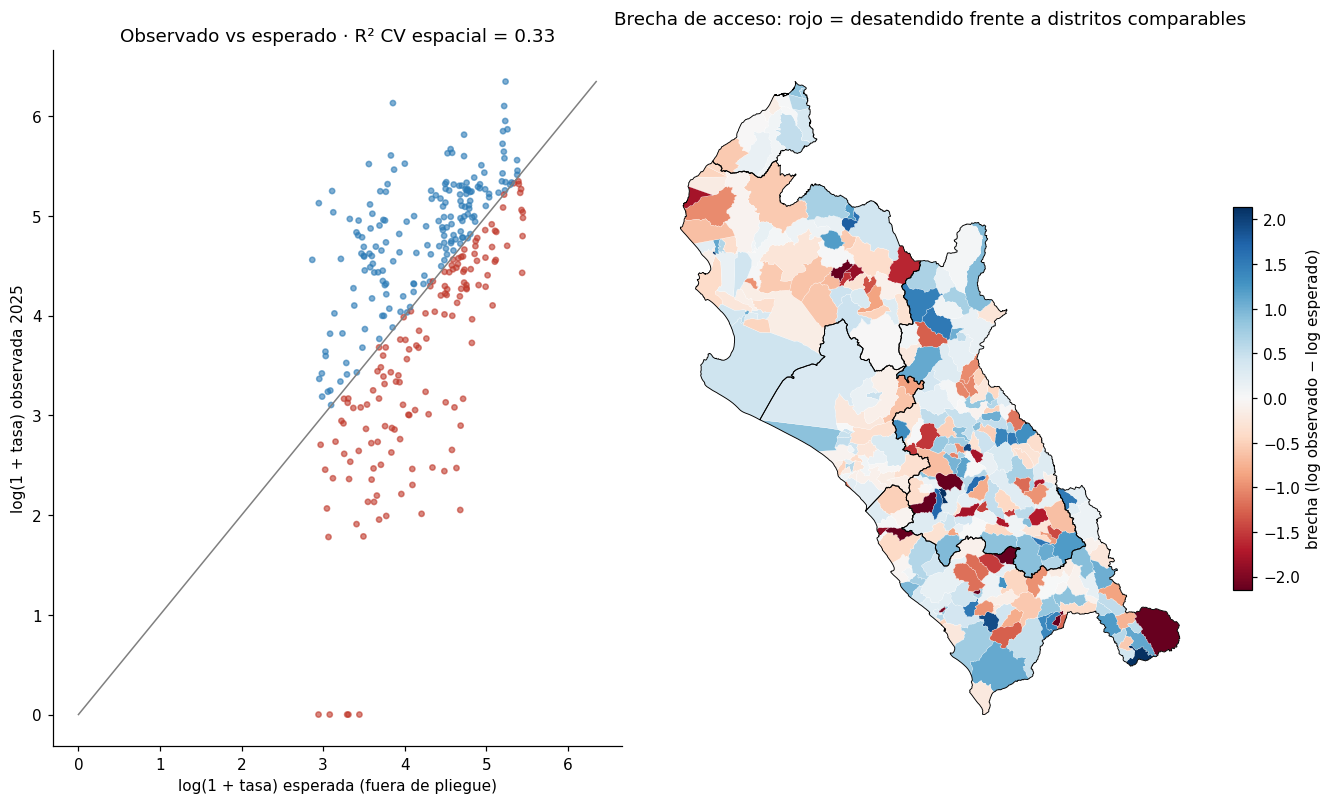

,distrito,provincia,departamento,tasa_obs,tasa_esperada,brecha
199,MOLLEBAMBA,SANTIAGO DE CHUCO,LA LIBERTAD,0.00,30.32,-3.44
108,SAN GREGORIO,SAN MIGUEL,CAJAMARCA,0.00,26.37,-3.31
166,PARANDAY,OTUZCO,LA LIBERTAD,0.00,25.97,-3.29
101,CALQUIS,SAN MIGUEL,CAJAMARCA,0.00,20.77,-3.08
181,ONGON,PATAZ,LA LIBERTAD,0.00,17.98,-2.94
285,SANTO DOMINGO,MORROPON,PIURA,6.78,106.86,-2.63
207,SAYAPULLO,GRAN CHIMU,LA LIBERTAD,6.48,66.13,-2.19
174,SAN JOSE,PACASMAYO,LA LIBERTAD,10.85,101.94,-2.16
138,ALTO TRUJILLO,TRUJILLO,LA LIBERTAD,10.48,87.79,-2.05
172,JEQUETEPEQUE,PACASMAYO,LA LIBERTAD,13.20,96.41,-1.93


In [10]:
gg = g[["ubigeo", "geometry"]].merge(corte, on="ubigeo")
deps = g.dissolve("departamento").reset_index()
lim = np.nanpercentile(np.abs(gg["brecha"]), 97)
fig, axes = plt.subplots(1, 2, figsize=(12, 7.2), constrained_layout=True)
axes[0].scatter(corte["y_esperado"], corte["y"], s=12, alpha=0.6,
                c=np.where(corte["brecha"] < 0, "#c0392b", "#2c7bb6"))
lims = [corte[["y", "y_esperado"]].min().min(), corte[["y", "y_esperado"]].max().max()]
axes[0].plot(lims, lims, color="grey", linewidth=1)
axes[0].set_xlabel("log(1 + tasa) esperada (fuera de pliegue)"); axes[0].set_ylabel("log(1 + tasa) observada 2025")
axes[0].set_title(f"Observado vs esperado · R² CV espacial = {cv_tab.loc[mejor, 'R² (CV espacial)']:.2f}")
gg.plot(column="brecha", cmap="RdBu", vmin=-lim, vmax=lim, ax=axes[1], edgecolor="white", linewidth=0.15,
        legend=True, legend_kwds={"label": "brecha (log observado − log esperado)", "shrink": 0.55})
deps.boundary.plot(ax=axes[1], color="black", linewidth=0.6)
axes[1].set_title("Brecha de acceso: rojo = desatendido frente a distritos comparables")
axes[1].set_axis_off()
fig.savefig(FIG / "08_brecha_acceso.png", bbox_inches="tight")
plt.show()

corte[["ubigeo", "distrito", "provincia", "departamento", "tasa_obs", "tasa_esperada", "brecha"]].round(3) \
    .to_csv(DATA / "brecha_acceso_2025.csv", index=False)
corte.sort_values("brecha")[["distrito", "provincia", "departamento", "tasa_obs", "tasa_esperada", "brecha"]].head(12).round(2)

## Hallazgos

1. **La red se triplicó y luego se ajustó.** Los canales pasaron de 22,7 mil (2017) a 87,8 mil (2023) y bajaron a
   73,3 mil en 2025. El retroceso de 2024 afecta a los cinco departamentos a la vez: es un choque común (cierre o
   consolidación de corresponsales), no un fenómeno local.
2. **La estructura espacial es estable.** El I de Moran del acceso se mantiene entre 0,20 y 0,24 todos los años
   (p = 0,001): la expansión no redujo la segregación entre zonas con y sin acceso.
3. **El entorno condiciona la trayectoria (Markov espacial).** La prueba de homogeneidad rechaza que las
   transiciones sean independientes del vecindario (Q = 146,3 con 80 gl, p < 0,0001; LR = 124,3, p = 0,001). Un
   distrito en el segundo quintil sube de quintil con probabilidad 0,36 si sus vecinos están en el quintil más
   alto y 0,12 si están en el segundo: hay difusión por contigüidad. El quintil más bajo es el más persistente
   (P = 0,79 de seguir ahí al año siguiente).
4. **El cambio anual de cada distrito no es predecible.** En validación de origen móvil (cuatro años de prueba),
   ningún modelo mejora a la persistencia (RMSE promedio 0,56 en todos) y la correlación de rangos del cambio es
   ≈ 0,08 en el mejor caso. Es un resultado negativo útil: priorizar por "crecimiento esperado" no tiene respaldo.
5. **El acceso potencial sí es modelable y la información espacial ayuda.** Con validación cruzada espacial por
   provincia, el Random Forest pasa de R² = 0,27 con covariables propias a 0,33 al agregar los rezagos WX y la
   posición, y el I de Moran de los residuos baja de 0,10 a 0,05. Pobreza y urbanización concentran 43% de la
   importancia SHAP.
6. **Brecha de acceso.** `data/processed/brecha_acceso_2025.csv` identifica distritos con mucho menos acceso que
   distritos de estructura similar: los 5 sin ningún canal (Mollebamba, San Gregorio, Paranday, Calquis, Ongón) y
   otros como Santo Domingo, Sayapullo, San José, Alto Trujillo y Jequetepeque, con tasas entre 7 y 16 veces
   menores a las esperadas. Esta brecha es el componente de **oportunidad** del score del notebook 09.